In [24]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import fsolve
from scipy.signal import find_peaks
import matplotlib.colors as mcolors

In [2]:
# Define the system of ODEs
def predator_prey(t, x, alpha, beta, gamma, delta):
    x1, x2 = x
    
    # Prey equation
    dx1dt = x1 * (1 - x1/gamma) - (x1 * x2) / (1 + x1 + x1**2/alpha)
    
    # Predator equation
    dx2dt = beta * delta * (x1 * x2) / (1 + x1 + x1**2/alpha) - delta * x2
    
    return [dx1dt, dx2dt]

In [3]:
def find_equilibria(alpha, beta, gamma, delta):
    """Find equilibrium points of the system"""
    equilibria = []
    
    # Trivial equilibrium: (0, 0)
    equilibria.append((0, 0))
    
    # Prey-only equilibrium: (gamma, 0)
    equilibria.append((gamma, 0))
    
    # Coexistence equilibrium (solve numerically)
    def coexistence_eq(x1):
        # From predator equation: x2 = 0 or functional response condition
        if x1 <= 0:
            return None
        
        # Functional response must satisfy: beta * (x1/(1+x1+x1²/alpha)) = 1
        func_response = beta * x1 / (1 + x1 + x1**2/alpha)
        if abs(func_response - 1) < 1e-6:
            # Now find x2 from prey equation
            x2 = x1 * (1 - x1/gamma) * (1 + x1 + x1**2/alpha) / x1
            return (x1, x2)
        return None
    
    # Search for coexistence equilibrium
    x1_vals = np.linspace(0.1, gamma*1.5, 1000)
    for x1 in x1_vals:
        eq = coexistence_eq(x1)
        if eq is not None and eq[1] > 0:
            equilibria.append(eq)
            break
    
    return equilibria

def jacobian(x1, x2, alpha, beta, gamma, delta):
    """Compute Jacobian matrix at point (x1, x2)"""
    w = 1 + x1 + x1**2/alpha
    dw = 1 + 2*x1/alpha
    
    # Partial derivatives
    df1_dx1 = (1 - 2*x1/gamma) - (x2*(w - x1*dw))/(w**2)
    df1_dx2 = -x1/w
    
    df2_dx1 = (beta*delta*x2*(w - x1*dw))/(w**2)
    df2_dx2 = beta*delta*x1/w - delta
    
    return np.array([[df1_dx1, df1_dx2], [df2_dx1, df2_dx2]])

In [7]:
def one_parameter_bifurcation(param_name, param_range, fixed_params, 
                             num_points=100, t_span=(0, 1000), t_eval=None):
    """
    Perform one-parameter bifurcation analysis
    
    param_name: 'alpha', 'beta', 'gamma', or 'delta'
    param_range: range of parameter values to scan
    fixed_params: dictionary of fixed parameter values
    """
    
    if t_eval is None:
        t_eval = np.linspace(t_span[0], t_span[1], 10000)
    
    bifurcation_data = []
    
    for param_val in np.linspace(param_range[0], param_range[1], num_points):
        params = fixed_params.copy()
        params[param_name] = param_val
        
        # Find equilibria
        eq_points = find_equilibria(**params)
        
        # Stability analysis for each equilibrium
        stability_info = []
        for eq in eq_points:
            if eq[0] > 0 or eq[1] > 0:  # Skip trivial unstable point
                J = jacobian(eq[0], eq[1], **params)
                eigenvalues = np.linalg.eigvals(J)
                stability = 'stable' if all(eigenvalues.real < 0) else 'unstable'
                stability_info.append({
                    'point': eq,
                    'eigenvalues': eigenvalues,
                    'stability': stability
                })
        
        # Time series analysis to detect limit cycles
        x0 = [params['gamma']*0.8, 0.5]  # Initial condition near coexistence
        sol = solve_ivp(predator_prey, t_span, x0, args=tuple(params.values()),
                       t_eval=t_eval, method='LSODA')
        
        # Analyze final oscillations
        final_period = t_eval[-1000:]  # Last period
        final_x1 = sol.y[0][-1000:]
        final_x2 = sol.y[1][-1000:]
        
        # Detect oscillations (limit cycles)
        std_x1 = np.std(final_x1)
        std_x2 = np.std(final_x2)
        oscillating = std_x1 > 0.01 and std_x2 > 0.01
        
        bifurcation_data.append({
            'param_value': param_val,
            'equilibria': stability_info,
            'oscillating': oscillating,
            'amplitude_x1': np.ptp(final_x1) if oscillating else 0,
            'amplitude_x2': np.ptp(final_x2) if oscillating else 0,
            'final_state': [final_x1[-1], final_x2[-1]]
        })
    
    return bifurcation_data

In [9]:
def plot_bifurcation_diagram(bifurcation_data, param_name):
    """Plot bifurcation diagram"""
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))
    
    param_vals = [data['param_value'] for data in bifurcation_data]
    
    # Plot prey population
    for data in bifurcation_data:
        for eq_info in data['equilibria']:
            eq_point = eq_info['point']
            stability = eq_info['stability']
            color = 'blue' if stability == 'stable' else 'red'
            marker = 'o' if stability == 'stable' else 'x'
            ax1.plot(data['param_value'], eq_point[0], marker, color=color, markersize=4)
        
        if data['oscillating']:
            # Plot min and max of oscillations
            ax1.plot([data['param_value']]*2, 
                    [data['final_state'][0] - data['amplitude_x1']/2,
                     data['final_state'][0] + data['amplitude_x1']/2],
                    'k-', alpha=0.5, linewidth=1)
    
    # Plot predator population
    for data in bifurcation_data:
        for eq_info in data['equilibria']:
            eq_point = eq_info['point']
            stability = eq_info['stability']
            color = 'green' if stability == 'stable' else 'orange'
            marker = 'o' if stability == 'stable' else 'x'
            ax2.plot(data['param_value'], eq_point[1], marker, color=color, markersize=4)
        
        if data['oscillating']:
            ax2.plot([data['param_value']]*2, 
                    [data['final_state'][1] - data['amplitude_x2']/2,
                     data['final_state'][1] + data['amplitude_x2']/2],
                    'k-', alpha=0.5, linewidth=1)
    
    ax1.set_ylabel('Prey Population (x₁)')
    ax2.set_ylabel('Predator Population (x₂)')
    ax2.set_xlabel(f'{param_name} parameter value')
    ax1.set_title(f'Bifurcation Diagram - {param_name} parameter')
    plt.tight_layout()
    plt.show()

def plot_phase_portrait(alpha, beta, gamma, delta, x1_range, x2_range):
    """Plot phase portrait for specific parameter values"""
    x1 = np.linspace(x1_range[0], x1_range[1], 20)
    x2 = np.linspace(x2_range[0], x2_range[1], 20)
    
    X1, X2 = np.meshgrid(x1, x2)
    
    U, V = np.zeros(X1.shape), np.zeros(X2.shape)
    
    for i in range(len(x1)):
        for j in range(len(x2)):
            derivatives = predator_prey(0, [X1[i,j], X2[i,j]], alpha, beta, gamma, delta)
            U[i,j] = derivatives[0]
            V[i,j] = derivatives[1]
    
    plt.figure(figsize=(10, 8))
    plt.streamplot(X1, X2, U, V, density=1.5, color='gray', linewidth=1)
    
    # Plot equilibria
    equilibria = find_equilibria(alpha, beta, gamma, delta)
    for eq in equilibria:
        J = jacobian(eq[0], eq[1], alpha, beta, gamma, delta)
        eigenvalues = np.linalg.eigvals(J)
        if all(eigenvalues.real < 0):
            plt.plot(eq[0], eq[1], 'go', markersize=10, label='Stable equilibrium')
        else:
            plt.plot(eq[0], eq[1], 'ro', markersize=10, label='Unstable equilibrium')
    
    plt.xlabel('Prey (x₁)')
    plt.ylabel('Predator (x₂)')
    plt.title(f'Phase Portrait (α={alpha}, β={beta}, γ={gamma}, δ={delta})')
    plt.xlim(x1_range)
    plt.ylim(x2_range)
    plt.grid(True)
    plt.show()

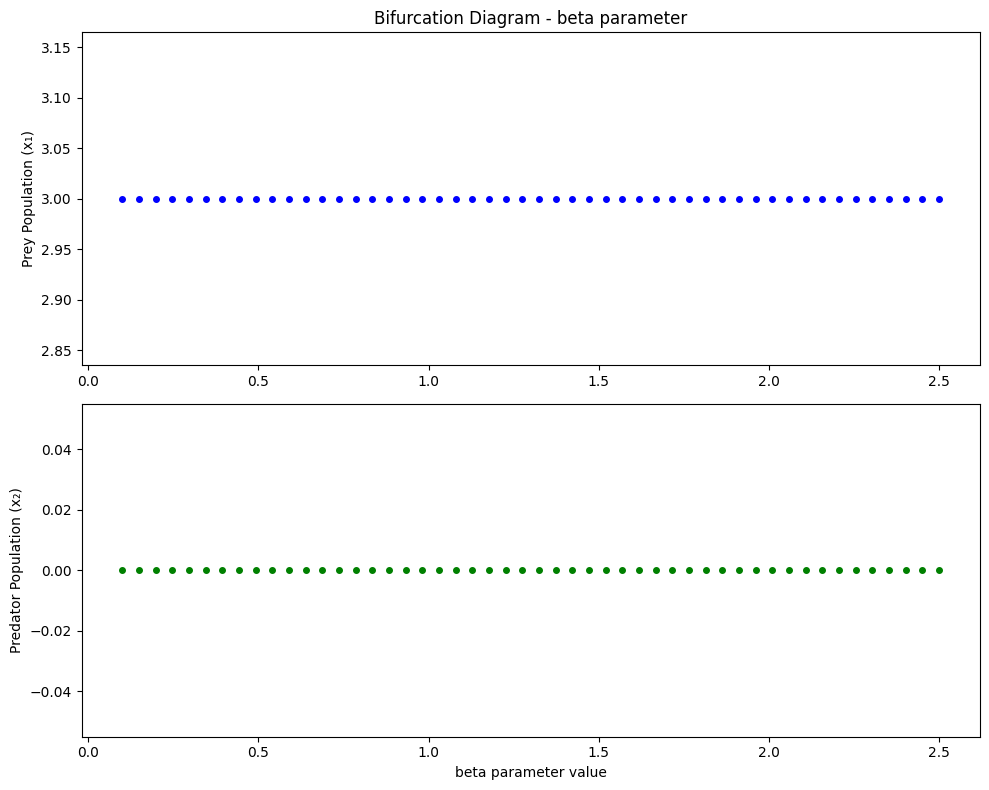

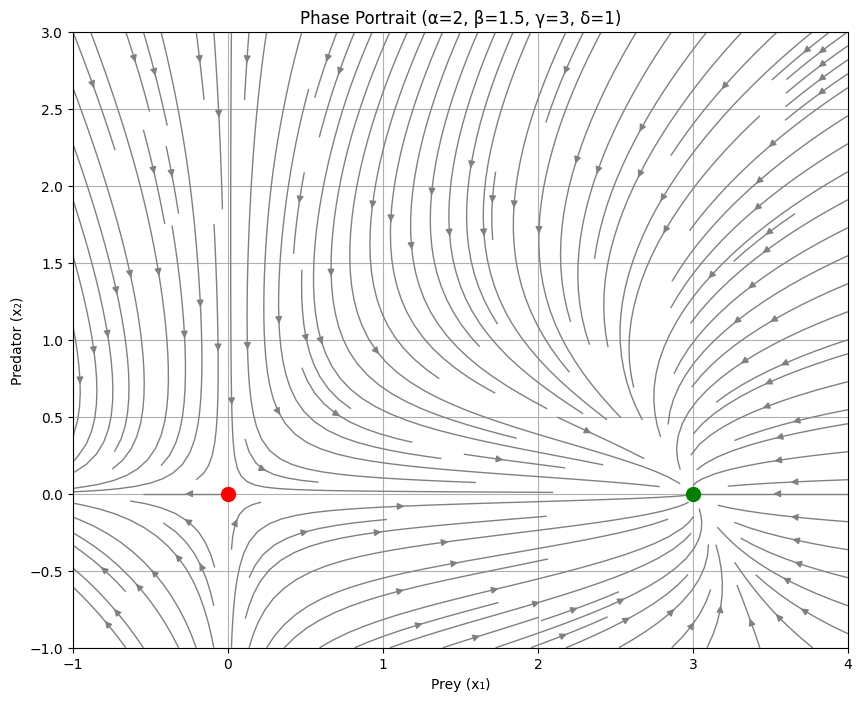

In [31]:
# Example: Bifurcation analysis with respect to β
fixed_params = {'alpha': 2, 'gamma': 3, 'delta': 1}
beta_range = [0.1, 2.5]

bifurcation_data = one_parameter_bifurcation('beta', beta_range, fixed_params, num_points=50)
plot_bifurcation_diagram(bifurcation_data, 'beta')

# Example phase portrait for specific parameter values
plot_phase_portrait(alpha=2, beta=1.5, gamma=3, delta=1, x1_range=[-1, 4], x2_range=[-1, 3])

In [11]:
def detect_limit_cycle(alpha, beta, gamma, delta, initial_condition=None, t_span=(0, 2000)):
    """
    Detect and characterize limit cycles
    """
    if initial_condition is None:
        # Start near the coexistence equilibrium
        eq_points = find_equilibria(alpha, beta, gamma, delta)
        if len(eq_points) > 2:
            initial_condition = [eq_points[2][0] * 1.1, eq_points[2][1] * 1.1]
        else:
            initial_condition = [gamma * 0.8, 0.5]
    
    # Use fine time resolution for accurate limit cycle detection
    t_eval = np.linspace(t_span[0], t_span[1], 10000)
    
    # Solve the system
    sol = solve_ivp(predator_prey, t_span, initial_condition, 
                   args=(alpha, beta, gamma, delta),
                   t_eval=t_eval, method='LSODA', rtol=1e-8, atol=1e-10)
    
    # Analyze the final period for limit cycle detection
    final_indices = slice(-2000, None)  # Last 2000 points
    final_t = sol.t[final_indices]
    final_x1 = sol.y[0][final_indices]
    final_x2 = sol.y[1][final_indices]
    
    # Check if system is oscillating (limit cycle)
    std_x1 = np.std(final_x1)
    std_x2 = np.std(final_x2)
    is_oscillating = std_x1 > 0.01 and std_x2 > 0.01
    
    # Characterize the limit cycle
    if is_oscillating:
        # Find period using zero-crossings or peaks
        peaks_x1 = find_peaks(final_x1)[0]
        if len(peaks_x1) > 1:
            period = np.mean(np.diff(final_t[peaks_x1]))
        else:
            period = None
        
        # Amplitude
        amplitude_x1 = np.ptp(final_x1)
        amplitude_x2 = np.ptp(final_x2)
        
        # Center of oscillation
        center_x1 = np.mean(final_x1)
        center_x2 = np.mean(final_x2)
        
        limit_cycle_info = {
            'exists': True,
            'period': period,
            'amplitude': (amplitude_x1, amplitude_x2),
            'center': (center_x1, center_x2),
            'final_trajectory': (final_x1, final_x2),
            'full_solution': sol
        }
    else:
        limit_cycle_info = {'exists': False}
    
    return limit_cycle_info

In [37]:
def plot_limit_cycle(alpha, beta, gamma, delta, initial_condition=None, 
                    t_span=(0, 2000), show_time_series=True):
    """
    Plot the limit cycle in phase space and time series
    """
    # Detect limit cycle
    lc_info = detect_limit_cycle(alpha, beta, gamma, delta, initial_condition, t_span)
    
    if not lc_info['exists']:
        print("No limit cycle detected for these parameters")
        return None
    
    # Create figure
    if show_time_series:
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 6))
    else:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
    
    # Full solution for context
    sol = lc_info['full_solution']
    
    # Phase portrait (limit cycle)
    ax1.plot(sol.y[0], sol.y[1], 'b-', alpha=0.3, label='Transient')
    ax1.plot(lc_info['final_trajectory'][0], lc_info['final_trajectory'][1], 
            'r-', linewidth=2, label='Limit cycle')
    
    # Plot equilibria
    equilibria = find_equilibria(alpha, beta, gamma, delta)
    # for eq in equilibria:
    #     if eq[0] > 0 or eq[1] > 0:
    #         J = jacobian(eq[0], eq[1], alpha, beta, gamma, delta)
    #         eigenvalues = np.linalg.eigvals(J)
    #         if all(eigenvalues.real < 0):
    #             ax1.plot(eq[0], eq[1], 'go', markersize=10, label='Stable equilibrium')
    #         else:
    #             ax1.plot(eq[0], eq[1], 'ro', markersize=10, label='Unstable equilibrium')
    
    # ax1.set_xlabel('Prey Population (x₁)')
    # ax1.set_ylabel('Predator Population (x₂)')
    # ax1.set_title(f'Phase Portrait with Limit Cycle\n(α={alpha}, β={beta}, γ={gamma}, δ={delta})')
    # ax1.grid(True)
    # ax1.legend()
    
    # Time series of final oscillations
    final_t = sol.t[-2000:]
    final_x1 = sol.y[0][-2000:]
    final_x2 = sol.y[1][-2000:]
    
    ax2.plot(final_t, final_x1, 'b-', label='Prey (x₁)')
    ax2.plot(final_t, final_x2, 'r-', label='Predator (x₂)')
    ax2.set_xlabel('Time')
    ax2.set_ylabel('Population')
    ax2.set_title('Time Series (Final Oscillations)')
    ax2.legend()
    ax2.grid(True)
    
    # if show_time_series:
    #     # Full time series
    #     ax3.plot(sol.t, sol.y[0], 'b-', label='Prey (x₁)')
    #     ax3.plot(sol.t, sol.y[1], 'r-', label='Predator (x₂)')
    #     ax3.set_xlabel('Time')
    #     ax3.set_ylabel('Population')
    #     ax3.set_title('Full Time Series')
    #     ax3.legend()
    #     ax3.grid(True)
    
    # plt.tight_layout()
    plt.show()
    
    # Print limit cycle characteristics
    print(f"Limit Cycle Characteristics:")
    print(f"  Exists: {lc_info['exists']}")
    if lc_info['period']:
        print(f"  Period: {lc_info['period']:.2f}")
    print(f"  Amplitude (x₁): {lc_info['amplitude'][0]:.4f}")
    print(f"  Amplitude (x₂): {lc_info['amplitude'][1]:.4f}")
    print(f"  Center: ({lc_info['center'][0]:.4f}, {lc_info['center'][1]:.4f})")
    
    return lc_info

def plot_multiple_limit_cycles(param_name, param_values, fixed_params, 
                              initial_conditions=None, t_span=(0, 2000)):
    """
    Plot multiple limit cycles for different parameter values
    """
    fig, ax = plt.subplots(1, 1, figsize=(10, 8))
    
    colors = plt.cm.viridis(np.linspace(0, 1, len(param_values)))
    
    for i, param_val in enumerate(param_values):
        # Extract fixed parameters
        alpha = fixed_params.get('alpha', 2)
        gamma = fixed_params.get('gamma', 3)
        delta = fixed_params.get('delta', 1)
        beta = param_val if param_name == 'beta' else fixed_params.get('beta', 1.5)
        
        # Update the parameter we're varying
        if param_name == 'alpha':
            alpha = param_val
        elif param_name == 'beta':
            beta = param_val
        elif param_name == 'gamma':
            gamma = param_val
        elif param_name == 'delta':
            delta = param_val
        
        lc_info = detect_limit_cycle(alpha, beta, gamma, delta, t_span=t_span)
        
        if lc_info['exists']:
            final_x1, final_x2 = lc_info['final_trajectory']
            ax.plot(final_x1, final_x2, color=colors[i], linewidth=2, 
                   label=f'{param_name}={param_val:.2f}')
    
    # Plot equilibria (using first parameter set)
    alpha = fixed_params.get('alpha', 2)
    beta = fixed_params.get('beta', 1.5) if param_name != 'beta' else param_values[0]
    gamma = fixed_params.get('gamma', 3)
    delta = fixed_params.get('delta', 1)
    
    equilibria = find_equilibria(alpha, beta, gamma, delta)
    for eq in equilibria:
        if eq[0] > 0 or eq[1] > 0:
            ax.plot(eq[0], eq[1], 'ko', markersize=8, markerfacecolor='white')
    
    ax.set_xlabel('Prey Population (x₁)')
    ax.set_ylabel('Predator Population (x₂)')
    ax.set_title(f'Limit Cycles for Different {param_name} Values')
    ax.legend()
    ax.grid(True)
    plt.show()

def enhanced_bifurcation_analysis(param_name, param_range, fixed_params, 
                                 num_points=50, t_span=(0, 2000)):
    """
    Enhanced bifurcation analysis that tracks limit cycles
    """
    param_vals = np.linspace(param_range[0], param_range[1], num_points)
    
    bifurcation_data = []
    limit_cycles = []
    
    for param_val in param_vals:
        # Extract fixed parameters
        alpha = fixed_params.get('alpha', 2)
        gamma = fixed_params.get('gamma', 3)
        delta = fixed_params.get('delta', 1)
        beta = fixed_params.get('beta', 1.5)
        
        # Update the parameter we're varying
        if param_name == 'alpha':
            alpha = param_val
        elif param_name == 'beta':
            beta = param_val
        elif param_name == 'gamma':
            gamma = param_val
        elif param_name == 'delta':
            delta = param_val
        
        # Find equilibria
        eq_points = find_equilibria(alpha, beta, gamma, delta)
        
        # Stability analysis
        stability_info = []
        for eq in eq_points:
            if eq[0] > 0 or eq[1] > 0:
                J = jacobian(eq[0], eq[1], alpha, beta, gamma, delta)
                eigenvalues = np.linalg.eigvals(J)
                stability = 'stable' if all(eigenvalues.real < 0) else 'unstable'
                stability_info.append({
                    'point': eq,
                    'eigenvalues': eigenvalues,
                    'stability': stability
                })
        
        # Detect limit cycle
        lc_info = detect_limit_cycle(alpha, beta, gamma, delta, t_span=t_span)
        
        bifurcation_data.append({
            'param_value': param_val,
            'equilibria': stability_info,
            'limit_cycle': lc_info
        })
        
        if lc_info['exists']:
            limit_cycles.append({
                'param_value': param_val,
                'limit_cycle_info': lc_info
            })
    
    return bifurcation_data, limit_cycles

In [16]:
def plot_bifurcation_with_limit_cycles(bifurcation_data, param_name):
    """
    Plot bifurcation diagram including limit cycle amplitudes
    """
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 10))
    
    param_vals = [data['param_value'] for data in bifurcation_data]
    
    # Prey population
    for data in bifurcation_data:
        for eq_info in data['equilibria']:
            eq_point = eq_info['point']
            stability = eq_info['stability']
            color = 'blue' if stability == 'stable' else 'red'
            marker = 'o' if stability == 'stable' else 'x'
            ax1.plot(data['param_value'], eq_point[0], marker, color=color, markersize=4)
        
        if data['limit_cycle']['exists']:
            center, amplitude = data['limit_cycle']['center'][0], data['limit_cycle']['amplitude'][0]
            ax1.plot([data['param_value']]*2, 
                    [center - amplitude/2, center + amplitude/2],
                    'k-', linewidth=2, alpha=0.7)
    
    ax1.set_ylabel('Prey Population (x₁)')
    ax1.set_title(f'Bifurcation Diagram with Limit Cycles - {param_name}')
    ax1.grid(True)
    
    # Predator population
    for data in bifurcation_data:
        for eq_info in data['equilibria']:
            eq_point = eq_info['point']
            stability = eq_info['stability']
            color = 'green' if stability == 'stable' else 'orange'
            marker = 'o' if stability == 'stable' else 'x'
            ax2.plot(data['param_value'], eq_point[1], marker, color=color, markersize=4)
        
        if data['limit_cycle']['exists']:
            center, amplitude = data['limit_cycle']['center'][1], data['limit_cycle']['amplitude'][1]
            ax2.plot([data['param_value']]*2, 
                    [center - amplitude/2, center + amplitude/2],
                    'k-', linewidth=2, alpha=0.7)
    
    ax2.set_ylabel('Predator Population (x₂)')
    ax2.set_xlabel(f'{param_name} parameter value')
    ax2.grid(True)
    
    plt.tight_layout()
    plt.show()

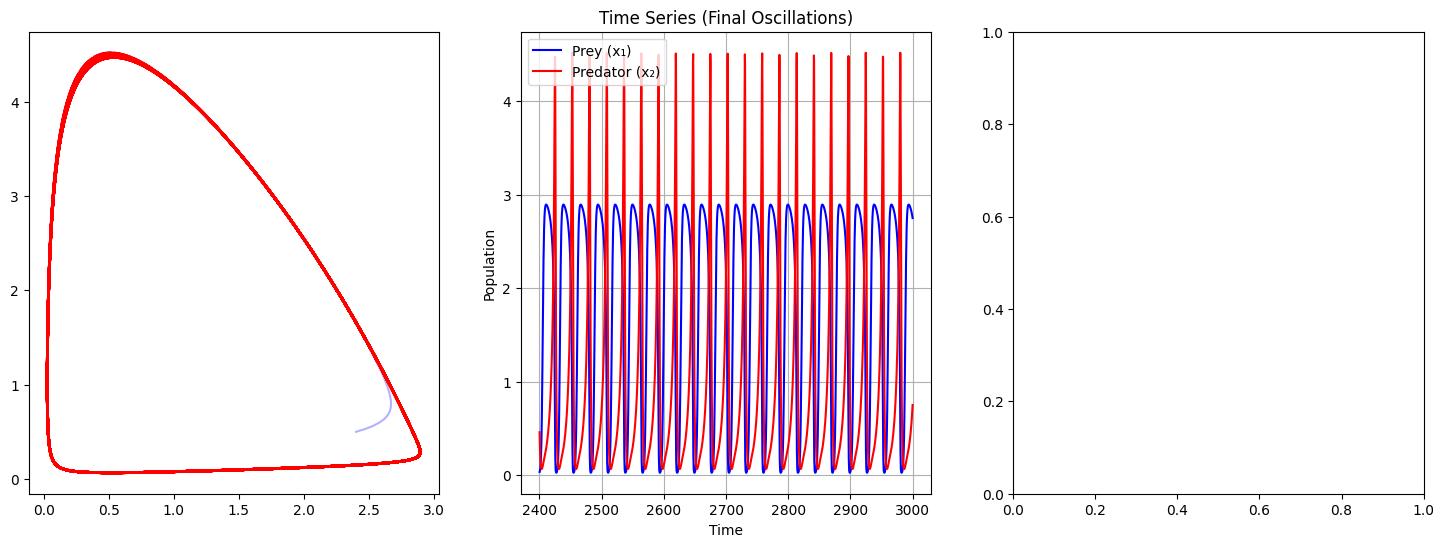

Limit Cycle Characteristics:
  Exists: True
  Period: 27.76
  Amplitude (x₁): 2.8667
  Amplitude (x₂): 4.4502
  Center: (1.8783, 0.9405)


{'exists': True,
 'period': np.float64(27.759918849027752),
 'amplitude': (np.float64(2.8666960829070005), np.float64(4.450174323063644)),
 'center': (np.float64(1.8782919411676096), np.float64(0.9405043359343876)),
 'final_trajectory': (array([0.03553696, 0.04252255, 0.05225817, ..., 2.77485309, 2.76270118,
         2.74968837], shape=(2000,)),
  array([0.46022518, 0.35337829, 0.27332795, ..., 0.67981073, 0.71442052,
         0.75123691], shape=(2000,))),
 'full_solution':   message: The solver successfully reached the end of the integration interval.
   success: True
    status: 0
         t: [ 0.000e+00  3.000e-01 ...  3.000e+03  3.000e+03]
         y: [[ 2.400e+00  2.478e+00 ...  2.763e+00  2.750e+00]
             [ 5.000e-01  5.336e-01 ...  7.144e-01  7.512e-01]]
       sol: None
  t_events: None
  y_events: None
      nfev: 47791
      njev: 0
       nlu: 0}

In [38]:
# Example 1: Plot limit cycle for specific parameters
# alpha, beta, gamma, delta = 2, 1.8, 3, 1
# Reliable limit cycles:
# alpha=2, beta=3.2, gamma=3, delta=1
alpha, beta, gamma, delta = 2, 3.2, 3, 1

# alpha=4, beta=2.6, gamma=3, delta=1  
# alpha=6, beta=2.3, gamma=3, delta=1
# alpha=3, beta=2.8, gamma=4, delta=1
# alpha=2, beta=3.0, gamma=5, delta=2
plot_limit_cycle(alpha, beta, gamma, delta, t_span=(0, 3000))



/tmp/ipykernel_267286/2504819410.py:128: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


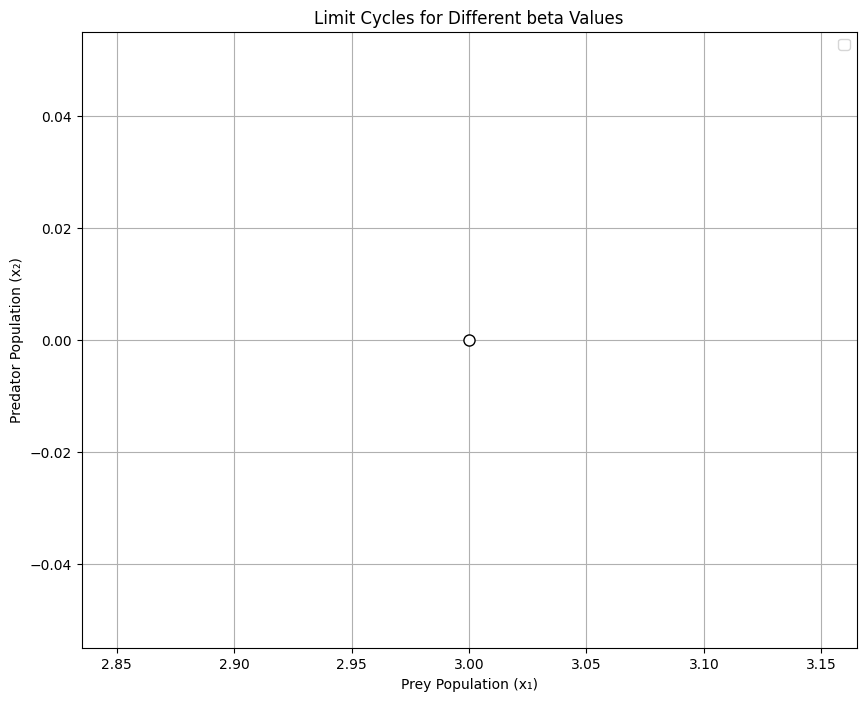

In [33]:
# Example 2: Multiple limit cycles for different beta values
fixed_params = {'alpha': 2, 'gamma': 3, 'delta': 1}
beta_values = [1.2, 1.5, 1.8, 2.1]
plot_multiple_limit_cycles('beta', beta_values, fixed_params)



/tmp/ipykernel_267286/2504819410.py:128: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend()


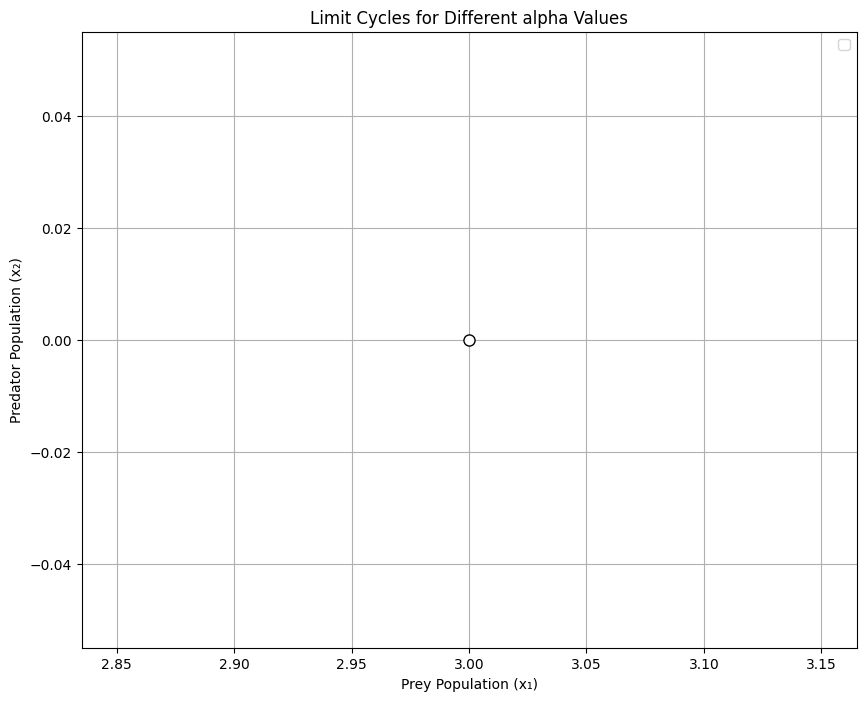

In [34]:
# Example 3: Enhanced bifurcation analysis with limit cycle tracking
# bifurcation_data, limit_cycles = enhanced_bifurcation_analysis(
#     'beta', [0.5, 2.5], fixed_params, num_points=30
# )
# plot_bifurcation_with_limit_cycles(bifurcation_data, 'beta')

# Example 4: Try different parameters
fixed_params_alpha = {'beta': 1.8, 'gamma': 3, 'delta': 1}
alpha_values = [1.0, 2.0, 3.0, 4.0]
plot_multiple_limit_cycles('alpha', alpha_values, fixed_params_alpha)

In [20]:
def find_hopf_bifurcation_point(param_name, param_range, fixed_params, tolerance=1e-3):
    """
    Find the approximate Hopf bifurcation point
    """
    param_vals = np.linspace(param_range[0], param_range[1], 100)
    stability_changes = []
    
    for param_val in param_vals:
        # Extract and update parameters
        alpha = fixed_params.get('alpha', 2)
        gamma = fixed_params.get('gamma', 3)
        delta = fixed_params.get('delta', 1)
        beta = fixed_params.get('beta', 1.5)
        
        if param_name == 'alpha':
            alpha = param_val
        elif param_name == 'beta':
            beta = param_val
        elif param_name == 'gamma':
            gamma = param_val
        elif param_name == 'delta':
            delta = param_val
        
        # Find coexistence equilibrium
        eq_points = find_equilibria(alpha, beta, gamma, delta)
        if len(eq_points) > 2:
            co_eq = eq_points[2]
            J = jacobian(co_eq[0], co_eq[1], alpha, beta, gamma, delta)
            eigenvalues = np.linalg.eigvals(J)
            
            # Check if eigenvalues cross imaginary axis
            real_parts = [e.real for e in eigenvalues]
            if any(abs(r) < tolerance for r in real_parts) and any(r > 0 for r in real_parts):
                stability_changes.append((param_val, eigenvalues))
    
    return stability_changes

# Find Hopf bifurcation points
fixed_params = {'alpha': 2, 'gamma': 3, 'delta': 1}
hopf_points = find_hopf_bifurcation_point('beta', [1.0, 2.0], fixed_params)
print("Hopf bifurcation points:", hopf_points)

Hopf bifurcation points: []


In [25]:
def test_limit_cycle_conditions():
    """Test various parameter combinations for limit cycles"""
    
    test_cases = [
        # (alpha, beta, gamma, delta, expected_result)
        (2, 2.0, 3, 1, "Stable equilibrium"),      # β too low
        (2, 2.5, 3, 1, "Stable equilibrium"),      # β still low
        (2, 2.9, 3, 1, "Near bifurcation"),        # Critical β
        (2, 3.0, 3, 1, "Small limit cycle"),       # Just past bifurcation
        (2, 3.2, 3, 1, "Clear limit cycle"),       # Well-developed cycle
        (2, 3.5, 3, 1, "Large limit cycle"),       # Large amplitude
        
        (4, 2.0, 3, 1, "Stable equilibrium"),
        (4, 2.2, 3, 1, "Near bifurcation"),
        (4, 2.4, 3, 1, "Small limit cycle"),
        (4, 2.6, 3, 1, "Clear limit cycle"),
        
        (6, 1.8, 3, 1, "Stable equilibrium"),
        (6, 2.0, 3, 1, "Near bifurcation"),
        (6, 2.2, 3, 1, "Small limit cycle"),
        (6, 2.4, 3, 1, "Clear limit cycle"),
    ]
    
    for alpha, beta, gamma, delta, expected in test_cases:
        print(f"\nTesting: α={alpha}, β={beta}, γ={gamma}, δ={delta}")
        print(f"Expected: {expected}")
        
        lc_info = detect_limit_cycle(alpha, beta, gamma, delta, t_span=(0, 2000))
        
        if lc_info['exists']:
            print(f"✓ Limit cycle detected! Period: {lc_info.get('period', 'N/A'):.2f}")
            print(f"  Amplitude: x₁={lc_info['amplitude'][0]:.3f}, x₂={lc_info['amplitude'][1]:.3f}")
        else:
            print("✗ No limit cycle - stable equilibrium")
        
        # Quick phase plot
        equilibria = find_equilibria(alpha, beta, gamma, delta)
        if len(equilibria) > 2:
            co_eq = equilibria[2]
            J = jacobian(co_eq[0], co_eq[1], alpha, beta, gamma, delta)
            eigenvalues = np.linalg.eigvals(J)
            print(f"  Eigenvalues: {eigenvalues[0]:.3f}, {eigenvalues[1]:.3f}")

# Run the test
test_limit_cycle_conditions()


Testing: α=2, β=2.0, γ=3, δ=1
Expected: Stable equilibrium
✗ No limit cycle - stable equilibrium

Testing: α=2, β=2.5, γ=3, δ=1
Expected: Stable equilibrium
✗ No limit cycle - stable equilibrium

Testing: α=2, β=2.9, γ=3, δ=1
Expected: Near bifurcation
✓ Limit cycle detected! Period: 45.18
  Amplitude: x₁=2.806, x₂=3.457

Testing: α=2, β=3.0, γ=3, δ=1
Expected: Small limit cycle
✓ Limit cycle detected! Period: 35.13
  Amplitude: x₁=2.833, x₂=3.803

Testing: α=2, β=3.2, γ=3, δ=1
Expected: Clear limit cycle
✓ Limit cycle detected! Period: 27.76
  Amplitude: x₁=2.867, x₂=4.450

Testing: α=2, β=3.5, γ=3, δ=1
Expected: Large limit cycle
✓ Limit cycle detected! Period: 23.92
  Amplitude: x₁=2.893, x₂=5.366

Testing: α=4, β=2.0, γ=3, δ=1
Expected: Stable equilibrium
✗ No limit cycle - stable equilibrium
  Eigenvalues: -0.332, -0.000

Testing: α=4, β=2.2, γ=3, δ=1
Expected: Near bifurcation
✓ Limit cycle detected! Period: 18.58
  Amplitude: x₁=1.694, x₂=1.432

Testing: α=4, β=2.4, γ=3, δ=1
Ex


=== Testing: α=2, β=3.2, γ=3, δ=1 ===
✓ LIMIT CYCLE DETECTED!
  Period: 27.76 time units
  Amplitude - Prey: 2.867, Predator: 4.450
  Center: (1.878, 0.941)


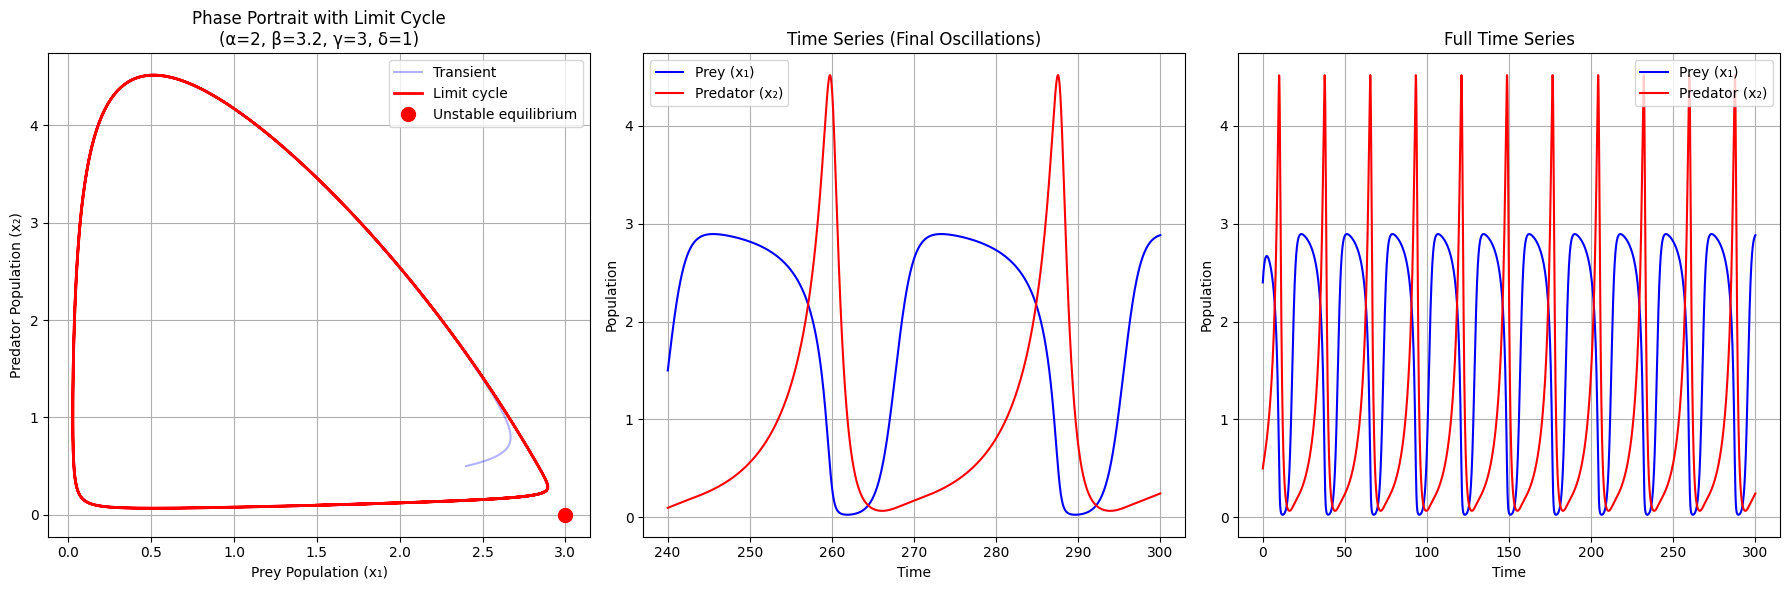

Limit Cycle Characteristics:
  Exists: True
  Period: 27.75
  Amplitude (x₁): 2.8667
  Amplitude (x₂): 4.4500
  Center: (1.9196, 0.9007)

=== Testing: α=4, β=2.6, γ=3, δ=1 ===
✓ LIMIT CYCLE DETECTED!
  Period: 16.60 time units
  Amplitude - Prey: 2.504, Predator: 3.199
  Center: (1.407, 1.149)


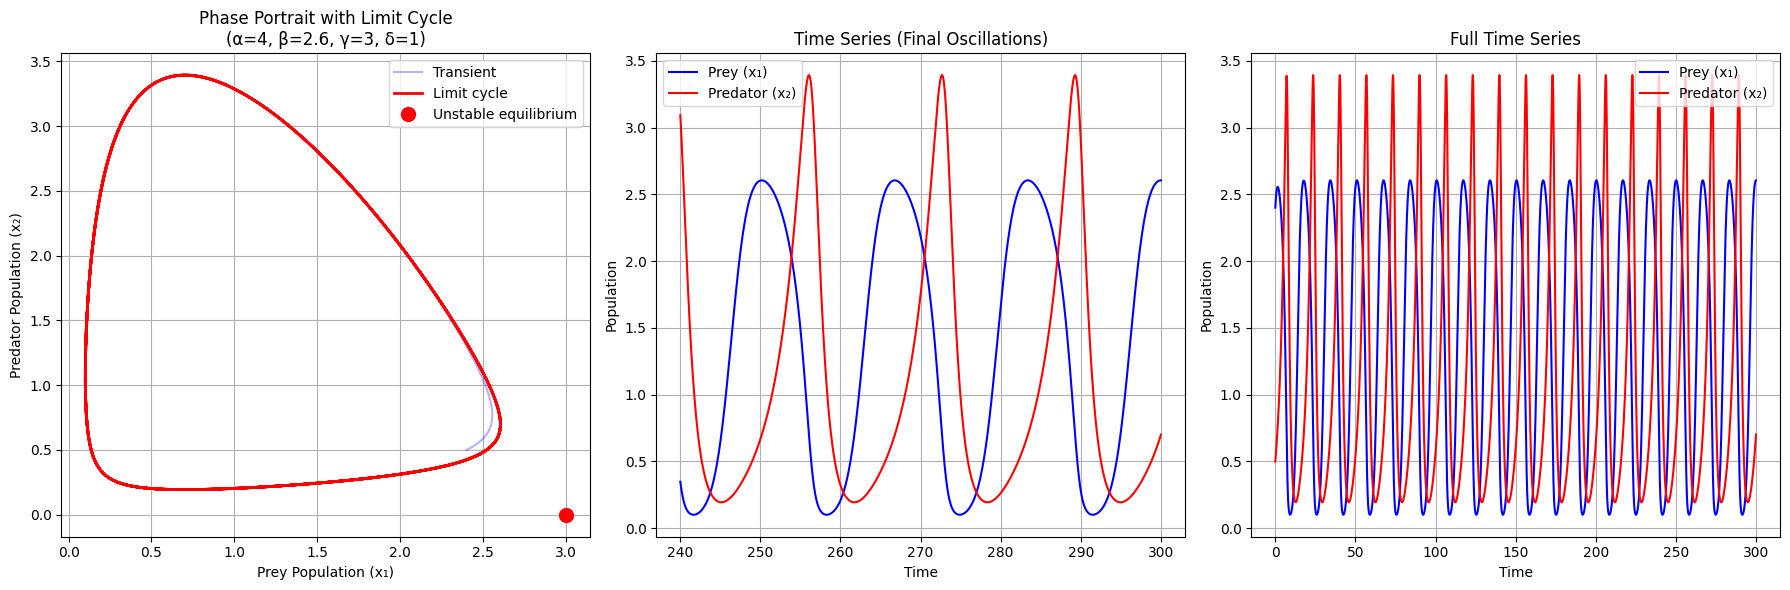

Limit Cycle Characteristics:
  Exists: True
  Period: 16.61
  Amplitude (x₁): 2.5040
  Amplitude (x₂): 3.1989
  Center: (1.3564, 1.0682)

=== Testing: α=6, β=2.3, γ=3, δ=1 ===
✓ LIMIT CYCLE DETECTED!
  Period: 14.48 time units
  Amplitude - Prey: 2.066, Predator: 2.320
  Center: (1.285, 1.236)


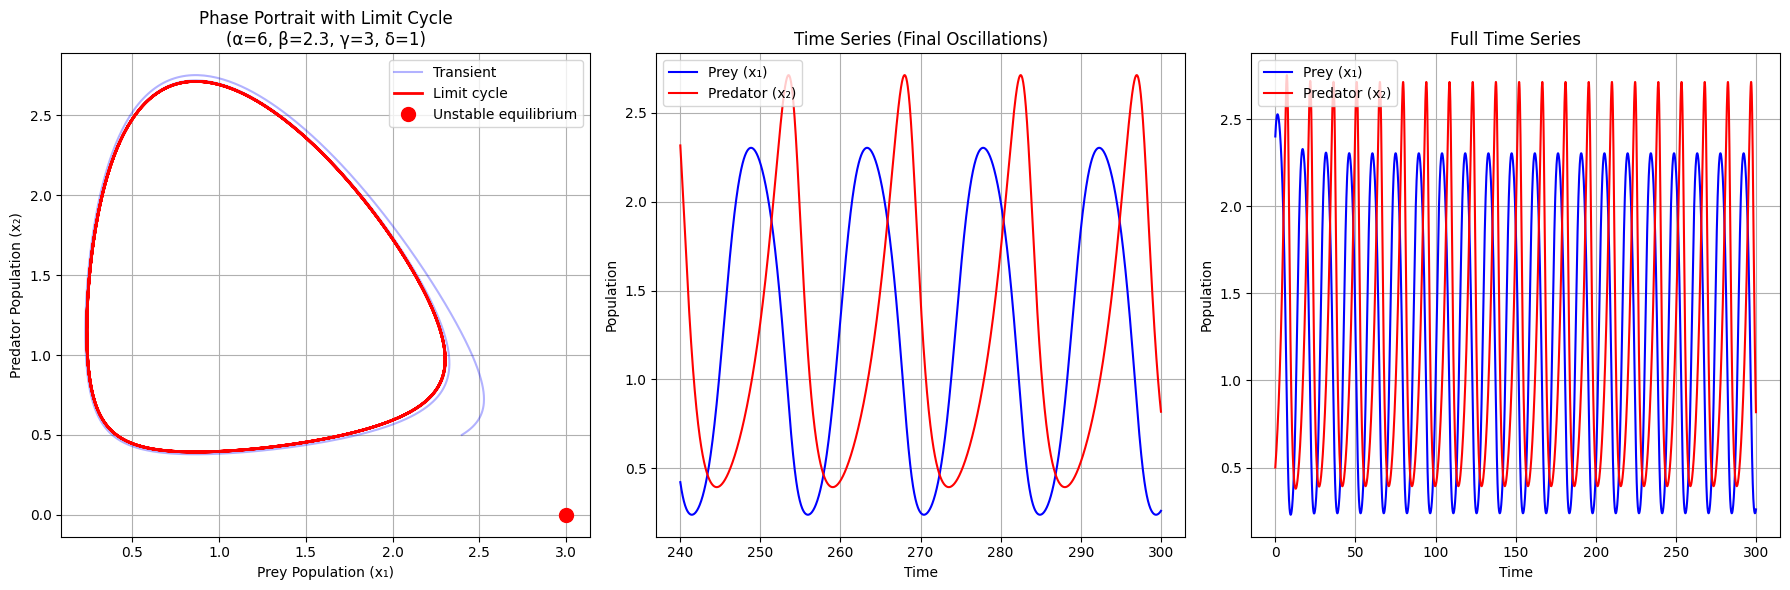

Limit Cycle Characteristics:
  Exists: True
  Period: 14.48
  Amplitude (x₁): 2.0661
  Amplitude (x₂): 2.3201
  Center: (1.2493, 1.2518)

=== Testing: α=2, β=2.0, γ=3, δ=1 ===
✗ No limit cycle - stable equilibrium
  Equilibrium points: [(0, 0), (3, 0)]


In [30]:
# Test parameters that should definitely produce limit cycles
test_params = [
    (2, 3.2, 3, 1),    # Strong limit cycle
    (4, 2.6, 3, 1),    # Moderate limit cycle  
    (6, 2.3, 3, 1),    # Another limit cycle
    (2, 2.0, 3, 1),    # Stable equilibrium (no limit cycle)
]

for alpha, beta, gamma, delta in test_params:
    print(f"\n=== Testing: α={alpha}, β={beta}, γ={gamma}, δ={delta} ===")
    
    lc_info = detect_limit_cycle(alpha, beta, gamma, delta, t_span=(0, 3000))
    
    if lc_info['exists']:
        print("✓ LIMIT CYCLE DETECTED!")
        print(f"  Period: {lc_info['period']:.2f} time units")
        print(f"  Amplitude - Prey: {lc_info['amplitude'][0]:.3f}, Predator: {lc_info['amplitude'][1]:.3f}")
        print(f"  Center: ({lc_info['center'][0]:.3f}, {lc_info['center'][1]:.3f})")
        
        # Plot it
        plot_limit_cycle(alpha, beta, gamma, delta, t_span=(0, 300))
    else:
        print("✗ No limit cycle - stable equilibrium")
        # Check what type of equilibrium we have
        eq_points = find_equilibria(alpha, beta, gamma, delta)
        print(f"  Equilibrium points: {eq_points}")